# 📊 Variable Selection in Linear Regression Models
### Methods Covered: Forward Selection | Backward Elimination | Recursive Feature Elimination (RFE)
**Dataset:** California Housing Dataset (sklearn built-in)

---
| Section | Description |
|---------|-------------|
| 1 | Import Libraries |
| 2 | Load & Explore Dataset |
| 3 | Preprocessing |
| 4 | Forward Selection |
| 5 | Backward Elimination |
| 6 | Recursive Feature Elimination (RFE) |
| 7 | RFECV — Auto Feature Count via Cross-Validation |
| 8 | Model Comparison Summary |
| 9 | Visualization |
| 10 | Assumptions Check (VIF, Residuals) |
| 11 | Conclusion & Best Practices |

---
## 📦 Section 1: Import Libraries

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Dataset
from sklearn.datasets import fetch_california_housing

# Models
from sklearn.linear_model import LinearRegression

# Feature Selection
from sklearn.feature_selection import RFE, RFECV

# Preprocessing
from sklearn.preprocessing import StandardScaler

# Model Evaluation
from sklearn.model_selection import cross_val_score, KFold, train_test_split
from sklearn.metrics import r2_score, mean_squared_error

# Statistical Modeling
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy import stats

print('✅ All libraries imported successfully!')
print(f'   NumPy: {np.__version__}')
print(f'   Pandas: {pd.__version__}')
print(f'   Scikit-learn imported')
print(f'   Statsmodels imported')

✅ All libraries imported successfully!
   NumPy: 2.0.2
   Pandas: 2.2.2
   Scikit-learn imported
   Statsmodels imported


---
## 📂 Section 2: Load & Explore the Dataset

We use the **California Housing Dataset** — a real-world dataset derived from the 1990 US Census.

| Feature | Description |
|---------|-------------|
| MedInc | Median income in block group |
| HouseAge | Median house age in block group |
| AveRooms | Average number of rooms per household |
| AveBedrms | Average number of bedrooms per household |
| Population | Block group population |
| AveOccup | Average household occupancy |
| Latitude | Block group latitude |
| Longitude | Block group longitude |
| **MedHouseVal** | **Target: Median house value (in $100,000s)** |

In [12]:
# Load dataset
housing = fetch_california_housing()
X = pd.DataFrame(housing.data, columns=housing.feature_names)
y = pd.Series(housing.target, name='MedHouseValue')

print('=' * 50)
print('CALIFORNIA HOUSING DATASET')
print('=' * 50)
print(f'Shape          : {X.shape}')
print(f'Features       : {list(X.columns)}')
print(f'Target         : {y.name}')
print(f'Missing Values : {X.isnull().sum().sum()}')

CALIFORNIA HOUSING DATASET
Shape          : (20640, 8)
Features       : ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Target         : MedHouseValue
Missing Values : 0


In [13]:
# First look at the data
print('First 5 rows of features:')
X.head()

First 5 rows of features:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [14]:
# Descriptive statistics
print('Descriptive Statistics:')
pd.concat([X, y], axis=1).describe().round(3)

Descriptive Statistics:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseValue
count,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000
mean,3.871,28.639,5.429,1.097,1425.477,3.071,35.632,-119.570,2.069
std,1.900,12.586,2.474,0.474,1132.462,10.386,2.136,2.004,1.154
min,0.500,1.000,0.846,0.333,3.000,0.692,32.540,-124.350,0.150
25%,2.563,18.000,4.441,1.006,787.000,2.430,33.930,-121.800,1.196
50%,3.535,29.000,5.229,1.049,1166.000,2.818,34.260,-118.490,1.797
75%,4.743,37.000,6.052,1.100,1725.000,3.282,37.710,-118.010,2.647
max,15.000,52.000,141.909,34.067,35682.000,1243.333,41.950,-114.310,5.000


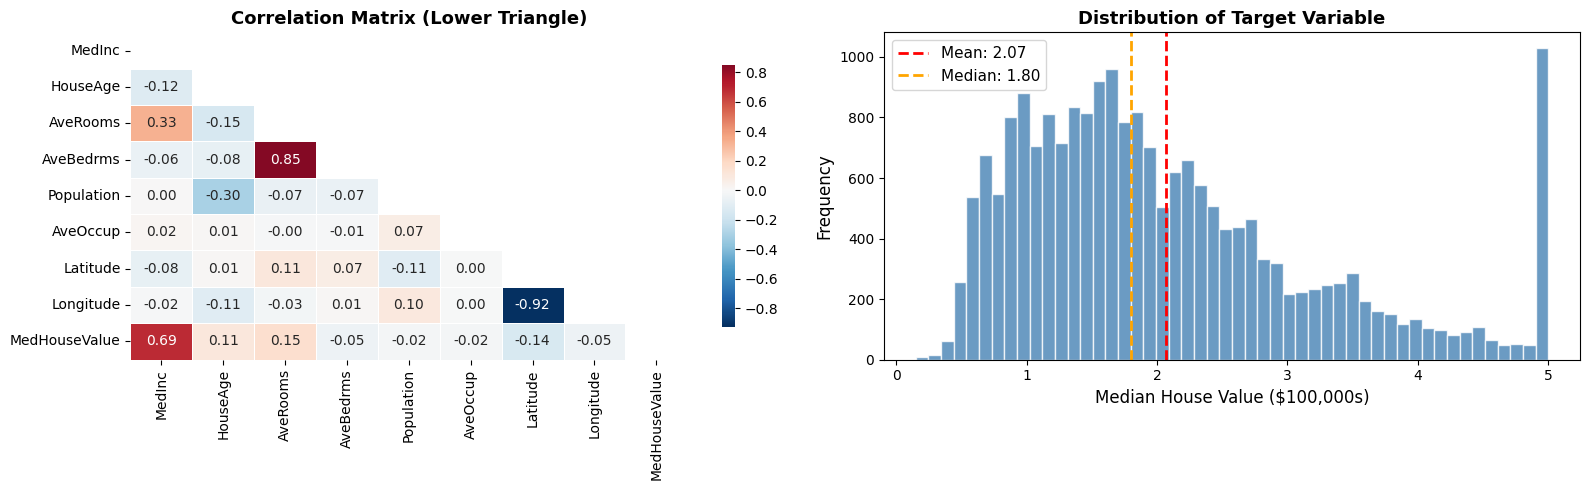

📊 EDA plots saved.


In [15]:
# Correlation Heatmap
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Heatmap
corr = pd.concat([X, y], axis=1).corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            mask=mask, ax=axes[0], linewidths=0.5,
            cbar_kws={'shrink': 0.8})
axes[0].set_title('Correlation Matrix (Lower Triangle)', fontsize=13, fontweight='bold')

# Target distribution
axes[1].hist(y, bins=50, color='steelblue', edgecolor='white', alpha=0.8)
axes[1].axvline(y.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {y.mean():.2f}')
axes[1].axvline(y.median(), color='orange', linestyle='--', linewidth=2, label=f'Median: {y.median():.2f}')
axes[1].set_xlabel('Median House Value ($100,000s)', fontsize=12)
axes[1].set_ylabel('Frequency', fontsize=12)
axes[1].set_title('Distribution of Target Variable', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=11)

plt.tight_layout()
plt.savefig('01_eda_plots.png', dpi=150, bbox_inches='tight')
plt.show()
print('📊 EDA plots saved.')

---
## ⚙️ Section 3: Preprocessing

> **Why standardize?** Regression coefficients depend on the scale of predictors. Standardizing ensures that RFE's importance ranking is based on relative contribution, not scale differences.

In [35]:
import numpy as np
from sklearn.linear_model import LinearRegression

# Simulate: both features equally important
np.random.seed(42)
income   = np.random.uniform(30000, 150000, 500)   # large scale
bedrooms = np.random.uniform(1, 6, 500)             # small scale
price    = 0.05 * income + 5000 * bedrooms + np.random.normal(0, 5000, 500)

X1 = np.column_stack([income, bedrooms])

# Without standardization
lr = LinearRegression().fit(X1, price)
print("Raw coefficients:")
print(f"  income   : {lr.coef_[0]:.4f}")   # will be tiny (~0.05)
print(f"  bedrooms : {lr.coef_[1]:.4f}")   # will be huge (~5000)

# With standardization
from sklearn.preprocessing import StandardScaler
X_scaled1 = StandardScaler().fit_transform(X1)
lr_scaled1 = LinearRegression().fit(X_scaled1, price)
print("\nStandardized coefficients:")
print(f"  income   : {lr_scaled.coef_[0]:.4f}")   # now comparable
print(f"  bedrooms : {lr_scaled.coef_[1]:.4f}")   # now comparable

Raw coefficients:
  income   : 0.0372
  bedrooms : 5039.7140

Standardized coefficients:
  income   : 1331.0884
  bedrooms : 7186.8292


In [16]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Standardize features
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X.columns,
    index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X.columns,
    index=X_test.index
)

# Also create a full standardized dataset for stepwise methods
X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns
)

print(f'Training set   : {X_train_scaled.shape}')
print(f'Test set       : {X_test_scaled.shape}')
print(f'\nStandardized feature stats (train):')
X_train_scaled.describe().round(3)

Training set   : (16512, 8)
Test set       : (4128, 8)

Standardized feature stats (train):


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,16512.000,16512.000,16512.000,16512.000,16512.000,16512.000,16512.000,16512.000
mean,-0.000,-0.000,-0.000,-0.000,-0.000,0.000,0.000,0.000
std,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
min,-1.775,-2.191,-1.904,-1.762,-1.252,-0.208,-1.448,-2.377
25%,-0.690,-0.842,-0.412,-0.208,-0.561,-0.058,-0.802,-1.111
50%,-0.176,0.031,-0.084,-0.109,-0.228,-0.024,-0.647,0.535
75%,0.469,0.666,0.262,0.008,0.263,0.016,0.972,0.784
max,5.839,1.856,57.167,56.647,30.127,107.116,2.952,2.629


---
## 🔼 Section 4: Forward Selection

**Algorithm:**
1. Start with an **empty model** (intercept only)
2. At each step, add the variable that most improves the model (lowest p-value)
3. Stop when no remaining variable has p-value < threshold (α)

```
Empty Model → Add best var → Refit → Add best var → ... → STOP
```

In [17]:
def forward_selection(X, y, significance_level=0.05, verbose=True):
    """
    Perform Forward Selection using OLS p-values.

    Parameters:
    -----------
    X : pd.DataFrame — predictor variables
    y : pd.Series    — response variable
    significance_level : float — threshold for adding a variable (default 0.05)
    verbose : bool — print step-by-step progress

    Returns:
    --------
    selected : list of selected feature names
    history  : DataFrame of step-by-step history
    """
    remaining = list(X.columns)
    selected = []
    history = []
    step = 0

    if verbose:
        print(f'   {"Step":<5} {"Added Feature":<20} {"p-value":<12} {"Adj. R²":<12} {"AIC"}')
        print('   ' + '-' * 65)

    while remaining:
        best_pval  = float('inf')
        best_feat  = None
        best_adjr2 = None
        best_aic   = None

        for feat in remaining:
            candidate = selected + [feat]
            X_cand = sm.add_constant(X[candidate])
            model  = sm.OLS(y, X_cand).fit()
            pval   = model.pvalues[feat]

            if pval < best_pval:
                best_pval  = pval
                best_feat  = feat
                best_adjr2 = model.rsquared_adj
                best_aic   = model.aic

        if best_pval < significance_level:
            step += 1
            selected.append(best_feat)
            remaining.remove(best_feat)
            history.append({
                'Step': step, 'Feature Added': best_feat,
                'p-value': round(best_pval, 6),
                'Adj. R²': round(best_adjr2, 4),
                'AIC': round(best_aic, 2)
            })
            if verbose:
                print(f'   {step:<5} {best_feat:<20} {best_pval:<12.6f} {best_adjr2:<12.4f} {best_aic:.2f}')
        else:
            if verbose:
                print(f'\n   ⛔ Stopping: best p-value = {best_pval:.4f} ≥ α = {significance_level}')
            break

    return selected, pd.DataFrame(history)

In [18]:
print('=' * 70)
print('FORWARD SELECTION  (α = 0.05)')
print('=' * 70)

fwd_features, fwd_history = forward_selection(X_scaled, y, significance_level=0.05)

print(f'\n✅ Selected {len(fwd_features)} features: {fwd_features}')

# Fit final model
X_fwd = sm.add_constant(X_scaled[fwd_features])
fwd_model = sm.OLS(y, X_fwd).fit()

print(f'\n📈 Final Forward Model Metrics:')
print(f'   R²        : {fwd_model.rsquared:.4f}')
print(f'   Adj. R²   : {fwd_model.rsquared_adj:.4f}')
print(f'   AIC       : {fwd_model.aic:.2f}')
print(f'   BIC       : {fwd_model.bic:.2f}')

FORWARD SELECTION  (α = 0.05)
   Step  Added Feature        p-value      Adj. R²      AIC
   -----------------------------------------------------------------
   1     MedInc               0.000000     0.4734       51249.34
   2     HouseAge             0.000000     0.5091       49803.43
   3     Latitude             0.000000     0.5171       49463.16
   4     Longitude            0.000000     0.5939       45887.71
   5     AveBedrms            0.000000     0.5987       45643.58
   6     AveRooms             0.000000     0.6049       45323.98
   7     AveOccup             0.000000     0.6061       45264.24

   ⛔ Stopping: best p-value = 0.4024 ≥ α = 0.05

✅ Selected 7 features: ['MedInc', 'HouseAge', 'Latitude', 'Longitude', 'AveBedrms', 'AveRooms', 'AveOccup']

📈 Final Forward Model Metrics:
   R²        : 0.6062
   Adj. R²   : 0.6061
   AIC       : 45264.24
   BIC       : 45327.72


In [19]:
# Step-by-step history table
print('Forward Selection Step History:')
fwd_history.style.background_gradient(subset=['Adj. R²'], cmap='Blues') \
                 .background_gradient(subset=['AIC'], cmap='Reds_r') \
                 .format({'p-value': '{:.6f}', 'Adj. R²': '{:.4f}', 'AIC': '{:.2f}'})

Forward Selection Step History:


,Step,Feature Added,p-value,Adj. R²,AIC
0,1,MedInc,0.000000,0.4734,51249.34
1,2,HouseAge,0.000000,0.5091,49803.43
2,3,Latitude,0.000000,0.5171,49463.16
3,4,Longitude,0.000000,0.5939,45887.71
4,5,AveBedrms,0.000000,0.5987,45643.58
5,6,AveRooms,0.000000,0.6049,45323.98
6,7,AveOccup,0.000000,0.6061,45264.24


In [20]:
# OLS Summary of Forward Selection Model
print('OLS Regression Results — Forward Selection:')
print(fwd_model.summary())

OLS Regression Results — Forward Selection:
                            OLS Regression Results                            
Dep. Variable:          MedHouseValue   R-squared:                       0.606
Model:                            OLS   Adj. R-squared:                  0.606
Method:                 Least Squares   F-statistic:                     4538.
Date:                Sun, 31 May 2026   Prob (F-statistic):               0.00
Time:                        03:31:33   Log-Likelihood:                -22624.
No. Observations:               20640   AIC:                         4.526e+04
Df Residuals:                   20632   BIC:                         4.533e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const   

---
## 🔽 Section 5: Backward Elimination

**Algorithm:**
1. Start with a **full model** containing all predictors
2. At each step, remove the variable with the highest p-value (least significant)
3. Stop when all remaining variables have p-value < threshold (α)

```
Full Model → Remove worst var → Refit → Remove worst var → ... → STOP
```

In [21]:
def backward_elimination(X, y, significance_level=0.05, verbose=True):
    """
    Perform Backward Elimination using OLS p-values.

    Parameters:
    -----------
    X : pd.DataFrame — predictor variables
    y : pd.Series    — response variable
    significance_level : float — threshold for removing a variable (default 0.05)
    verbose : bool — print step-by-step progress

    Returns:
    --------
    features : list of remaining feature names
    history  : DataFrame of step-by-step history
    """
    features = list(X.columns)
    history = []
    step = 0

    # Show initial full model
    X_curr = sm.add_constant(X[features])
    model  = sm.OLS(y, X_curr).fit()

    if verbose:
        print(f'   Initial model: {len(features)} features | R²={model.rsquared:.4f} | AIC={model.aic:.2f}')
        print(f'   {"Step":<5} {"Removed Feature":<20} {"p-value":<12} {"Adj. R²":<12} {"AIC"}')
        print('   ' + '-' * 65)

    while True:
        X_curr = sm.add_constant(X[features])
        model  = sm.OLS(y, X_curr).fit()

        pvals        = model.pvalues.drop('const')
        max_pval     = pvals.max()
        worst_feat   = pvals.idxmax()

        if max_pval > significance_level:
            step += 1
            features.remove(worst_feat)
            # Refit without removed feature for metrics
            X_new   = sm.add_constant(X[features])
            m_new   = sm.OLS(y, X_new).fit()
            history.append({
                'Step': step, 'Feature Removed': worst_feat,
                'p-value': round(max_pval, 6),
                'Adj. R²': round(m_new.rsquared_adj, 4),
                'AIC': round(m_new.aic, 2)
            })
            if verbose:
                print(f'   {step:<5} {worst_feat:<20} {max_pval:<12.6f} {m_new.rsquared_adj:<12.4f} {m_new.aic:.2f}')
        else:
            if verbose:
                print(f'\n   ✅ Stopping: all p-values < α = {significance_level}')
            break

    return features, pd.DataFrame(history)

In [22]:
print('=' * 70)
print('BACKWARD ELIMINATION  (α = 0.05)')
print('=' * 70)

bwd_features, bwd_history = backward_elimination(X_scaled, y, significance_level=0.05)

print(f'\n✅ Remaining {len(bwd_features)} features: {bwd_features}')

# Fit final model
X_bwd = sm.add_constant(X_scaled[bwd_features])
bwd_model = sm.OLS(y, X_bwd).fit()

print(f'\n📈 Final Backward Model Metrics:')
print(f'   R²        : {bwd_model.rsquared:.4f}')
print(f'   Adj. R²   : {bwd_model.rsquared_adj:.4f}')
print(f'   AIC       : {bwd_model.aic:.2f}')
print(f'   BIC       : {bwd_model.bic:.2f}')

BACKWARD ELIMINATION  (α = 0.05)
   Initial model: 8 features | R²=0.6062 | AIC=45265.54
   Step  Removed Feature      p-value      Adj. R²      AIC
   -----------------------------------------------------------------
   1     Population           0.402447     0.6061       45264.24

   ✅ Stopping: all p-values < α = 0.05

✅ Remaining 7 features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'AveOccup', 'Latitude', 'Longitude']

📈 Final Backward Model Metrics:
   R²        : 0.6062
   Adj. R²   : 0.6061
   AIC       : 45264.24
   BIC       : 45327.72


In [23]:
print('Backward Elimination Step History:')
if len(bwd_history) > 0:
    display(bwd_history.style.background_gradient(subset=['Adj. R²'], cmap='Blues')
                             .background_gradient(subset=['AIC'], cmap='Reds_r')
                             .format({'p-value': '{:.6f}', 'Adj. R²': '{:.4f}', 'AIC': '{:.2f}'}))
else:
    print('   ℹ️ No features were removed — all features are significant in the full model.')

Backward Elimination Step History:


,Step,Feature Removed,p-value,Adj. R²,AIC
0,1,Population,0.402447,0.6061,45264.24


In [24]:
# OLS Summary
print('OLS Regression Results — Backward Elimination:')
print(bwd_model.summary())

OLS Regression Results — Backward Elimination:
                            OLS Regression Results                            
Dep. Variable:          MedHouseValue   R-squared:                       0.606
Model:                            OLS   Adj. R-squared:                  0.606
Method:                 Least Squares   F-statistic:                     4538.
Date:                Sun, 31 May 2026   Prob (F-statistic):               0.00
Time:                        03:31:44   Log-Likelihood:                -22624.
No. Observations:               20640   AIC:                         4.526e+04
Df Residuals:                   20632   BIC:                         4.533e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const

---
## 🔁 Section 6: Recursive Feature Elimination (RFE)

**Algorithm:**
1. Fit model on all features
2. Rank features by **absolute coefficient value** (importance)
3. Remove the least important feature(s)
4. Repeat until desired number of features reached

> **Key difference:** RFE uses the model's own feature importance scores — not statistical p-values.

In [25]:
print('=' * 70)
print('RECURSIVE FEATURE ELIMINATION (RFE)')
print('=' * 70)

lr = LinearRegression()

# Test multiple feature counts to find the best
rfe_results = []
for n in range(1, len(X_scaled.columns) + 1):
    rfe_temp = RFE(estimator=LinearRegression(), n_features_to_select=n, step=1)
    rfe_temp.fit(X_scaled, y)
    feats = X_scaled.columns[rfe_temp.support_].tolist()
    lr_temp = LinearRegression().fit(X_scaled[feats], y)
    y_pred = lr_temp.predict(X_scaled[feats])
    r2 = r2_score(y, y_pred)
    rfe_results.append({'n_features': n, 'features': feats, 'R²': round(r2, 4)})

rfe_df = pd.DataFrame(rfe_results)

# Choose n=5 as representative
rfe = RFE(estimator=lr, n_features_to_select=5, step=1)
rfe.fit(X_scaled, y)

rfe_features = X_scaled.columns[rfe.support_].tolist()
rfe_ranking  = pd.Series(rfe.ranking_, index=X_scaled.columns, name='RFE Rank')

print('\n📊 Feature Rankings (1 = selected):')
print(rfe_ranking.sort_values().to_string())
print(f'\n✅ RFE Selected {len(rfe_features)} Features: {rfe_features}')

RECURSIVE FEATURE ELIMINATION (RFE)

📊 Feature Rankings (1 = selected):
MedInc        1
AveRooms      1
AveBedrms     1
Longitude     1
Latitude      1
HouseAge      2
AveOccup      3
Population    4

✅ RFE Selected 5 Features: ['MedInc', 'AveRooms', 'AveBedrms', 'Latitude', 'Longitude']


In [26]:
# Fit and evaluate RFE model
X_rfe_sm = sm.add_constant(X_scaled[rfe_features])
rfe_model = sm.OLS(y, X_rfe_sm).fit()

print('📈 RFE Model Metrics (n=5):')
print(f'   R²        : {rfe_model.rsquared:.4f}')
print(f'   Adj. R²   : {rfe_model.rsquared_adj:.4f}')
print(f'   AIC       : {rfe_model.aic:.2f}')
print(f'   BIC       : {rfe_model.bic:.2f}')

# Test set performance
lr_rfe = LinearRegression().fit(X_train_scaled[rfe_features], y_train)
y_pred_test = lr_rfe.predict(X_test_scaled[rfe_features])
print(f'\n   Test R²   : {r2_score(y_test, y_pred_test):.4f}')
print(f'   Test RMSE : {np.sqrt(mean_squared_error(y_test, y_pred_test)):.4f}')

📈 RFE Model Metrics (n=5):
   R²        : 0.5954
   Adj. R²   : 0.5953
   AIC       : 45818.49
   BIC       : 45866.10

   Test R²   : 0.5675
   Test RMSE : 0.7528


---
## 🔁✅ Section 7: RFECV — Automatic Feature Count via Cross-Validation

RFECV runs RFE inside a **k-fold cross-validation loop** at each step, selecting the number of features that maximizes average cross-validated performance.

> This eliminates the need to manually specify `n_features_to_select`.

In [27]:
print('=' * 70)
print('RFECV — RFE with Cross-Validation')
print('=' * 70)

cv = KFold(n_splits=5, shuffle=True, random_state=42)

rfecv = RFECV(
    estimator=LinearRegression(),
    step=1,
    cv=cv,
    scoring='r2',
    min_features_to_select=1
)
rfecv.fit(X_scaled, y)

rfecv_features = X_scaled.columns[rfecv.support_].tolist()

print(f'\n   Optimal number of features : {rfecv.n_features_}')
print(f'   Selected features          : {rfecv_features}')

# Cross-validated scores
cv_scores = cross_val_score(
    LinearRegression(), X_scaled[rfecv_features], y, cv=cv, scoring='r2'
)
print(f'\n   CV R² scores : {cv_scores.round(4)}')
print(f'   Mean CV R²   : {cv_scores.mean():.4f}')
print(f'   Std CV R²    : {cv_scores.std():.4f}')

RFECV — RFE with Cross-Validation

   Optimal number of features : 6
   Selected features          : ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Latitude', 'Longitude']

   CV R² scores : [0.575  0.6127 0.6074 0.6293 0.5883]
   Mean CV R²   : 0.6025
   Std CV R²    : 0.0190


In [28]:
# Fit RFECV model with statsmodels for full summary
X_rfecv_sm = sm.add_constant(X_scaled[rfecv_features])
rfecv_model = sm.OLS(y, X_rfecv_sm).fit()

print('📈 RFECV Model Metrics:')
print(f'   R²        : {rfecv_model.rsquared:.4f}')
print(f'   Adj. R²   : {rfecv_model.rsquared_adj:.4f}')
print(f'   AIC       : {rfecv_model.aic:.2f}')
print(f'   BIC       : {rfecv_model.bic:.2f}')

# Test set performance
lr_rfecv = LinearRegression().fit(X_train_scaled[rfecv_features], y_train)
y_pred_rfecv = lr_rfecv.predict(X_test_scaled[rfecv_features])
print(f'\n   Test R²   : {r2_score(y_test, y_pred_rfecv):.4f}')
print(f'   Test RMSE : {np.sqrt(mean_squared_error(y_test, y_pred_rfecv)):.4f}')

📈 RFECV Model Metrics:
   R²        : 0.6050
   Adj. R²   : 0.6049
   AIC       : 45323.98
   BIC       : 45379.52

   Test R²   : 0.5750
   Test RMSE : 0.7463


---
## 📋 Section 8: Model Comparison Summary

In [29]:
# Build comparison table
results = []

# Full model
X_full = sm.add_constant(X_scaled)
full_model = sm.OLS(y, X_full).fit()
lr_full = LinearRegression().fit(X_train_scaled, y_train)
test_r2_full = r2_score(y_test, lr_full.predict(X_test_scaled))

results.append({'Method': 'Full Model (all features)',
                'N Features': len(X_scaled.columns),
                'Features': ', '.join(X_scaled.columns),
                'Train R²': round(full_model.rsquared, 4),
                'Adj. R²': round(full_model.rsquared_adj, 4),
                'Test R²': round(test_r2_full, 4),
                'AIC': round(full_model.aic, 1),
                'BIC': round(full_model.bic, 1)})

# Forward Selection
lr_fwd_test = LinearRegression().fit(X_train_scaled[fwd_features], y_train)
results.append({'Method': 'Forward Selection',
                'N Features': len(fwd_features),
                'Features': ', '.join(fwd_features),
                'Train R²': round(fwd_model.rsquared, 4),
                'Adj. R²': round(fwd_model.rsquared_adj, 4),
                'Test R²': round(r2_score(y_test, lr_fwd_test.predict(X_test_scaled[fwd_features])), 4),
                'AIC': round(fwd_model.aic, 1),
                'BIC': round(fwd_model.bic, 1)})

# Backward Elimination
lr_bwd_test = LinearRegression().fit(X_train_scaled[bwd_features], y_train)
results.append({'Method': 'Backward Elimination',
                'N Features': len(bwd_features),
                'Features': ', '.join(bwd_features),
                'Train R²': round(bwd_model.rsquared, 4),
                'Adj. R²': round(bwd_model.rsquared_adj, 4),
                'Test R²': round(r2_score(y_test, lr_bwd_test.predict(X_test_scaled[bwd_features])), 4),
                'AIC': round(bwd_model.aic, 1),
                'BIC': round(bwd_model.bic, 1)})

# RFE
results.append({'Method': 'RFE (n=5)',
                'N Features': len(rfe_features),
                'Features': ', '.join(rfe_features),
                'Train R²': round(rfe_model.rsquared, 4),
                'Adj. R²': round(rfe_model.rsquared_adj, 4),
                'Test R²': round(r2_score(y_test, y_pred_test), 4),
                'AIC': round(rfe_model.aic, 1),
                'BIC': round(rfe_model.bic, 1)})

# RFECV
results.append({'Method': 'RFECV (auto)',
                'N Features': len(rfecv_features),
                'Features': ', '.join(rfecv_features),
                'Train R²': round(rfecv_model.rsquared, 4),
                'Adj. R²': round(rfecv_model.rsquared_adj, 4),
                'Test R²': round(r2_score(y_test, y_pred_rfecv), 4),
                'AIC': round(rfecv_model.aic, 1),
                'BIC': round(rfecv_model.bic, 1)})

df_results = pd.DataFrame(results)
display_cols = ['Method', 'N Features', 'Train R²', 'Adj. R²', 'Test R²', 'AIC', 'BIC']

print('=' * 80)
print('MODEL COMPARISON SUMMARY')
print('=' * 80)
df_results[display_cols].style \
    .background_gradient(subset=['Train R²', 'Adj. R²', 'Test R²'], cmap='Greens') \
    .background_gradient(subset=['AIC', 'BIC'], cmap='Reds_r') \
    .highlight_max(subset=['Test R²'], color='lightgreen') \
    .highlight_min(subset=['AIC'], color='lightyellow') \
    .format({'Train R²': '{:.4f}', 'Adj. R²': '{:.4f}', 'Test R²': '{:.4f}',
             'AIC': '{:.1f}', 'BIC': '{:.1f}'})

MODEL COMPARISON SUMMARY


,Method,N Features,Train R²,Adj. R²,Test R²,AIC,BIC
0,Full Model (all features),8,0.6062,0.6061,0.5758,45265.5,45337.0
1,Forward Selection,7,0.6062,0.6061,0.5757,45264.2,45327.7
2,Backward Elimination,7,0.6062,0.6061,0.5757,45264.2,45327.7
3,RFE (n=5),5,0.5954,0.5953,0.5675,45818.5,45866.1
4,RFECV (auto),6,0.6050,0.6049,0.5750,45324.0,45379.5


---
## 📉 Section 9: Visualizations

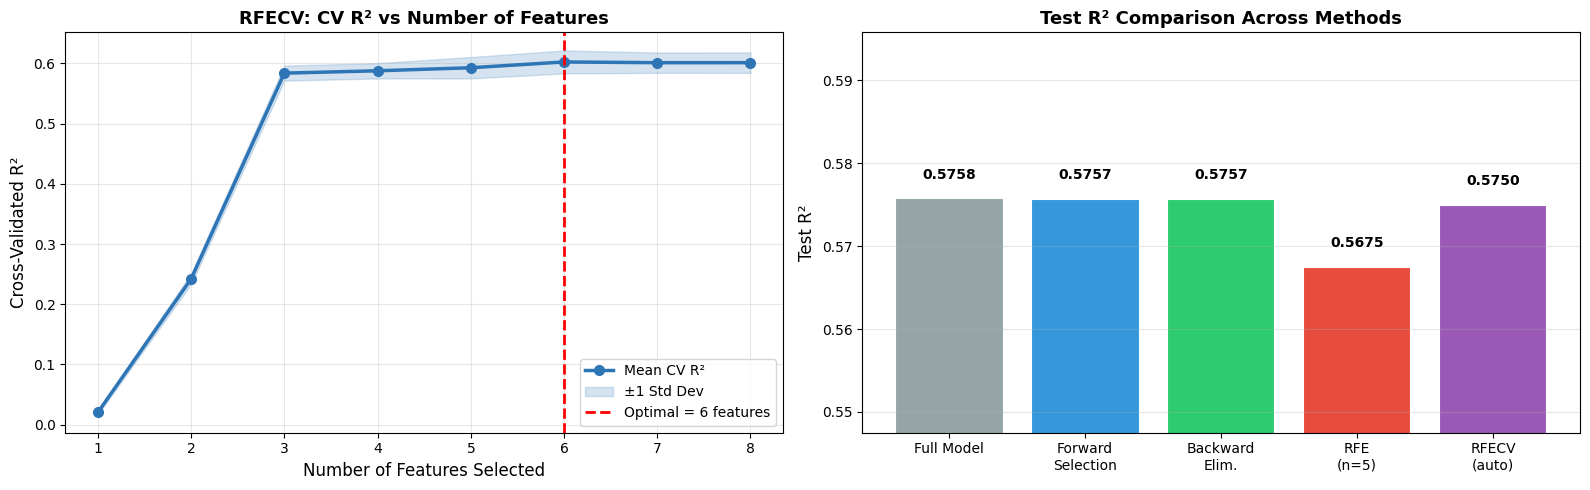

In [30]:
# Plot 1: RFECV Cross-Validated R² vs Number of Features
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# RFECV scores
n_features_range = range(1, len(rfecv.cv_results_['mean_test_score']) + 1)
mean_scores = rfecv.cv_results_['mean_test_score']
std_scores  = rfecv.cv_results_['std_test_score']

axes[0].plot(n_features_range, mean_scores, 'o-', color='#2E75B6', lw=2.5, ms=7, label='Mean CV R²')
axes[0].fill_between(n_features_range,
                     mean_scores - std_scores,
                     mean_scores + std_scores,
                     alpha=0.2, color='#2E75B6', label='±1 Std Dev')
axes[0].axvline(rfecv.n_features_, color='red', linestyle='--', lw=2,
                label=f'Optimal = {rfecv.n_features_} features')
axes[0].set_xlabel('Number of Features Selected', fontsize=12)
axes[0].set_ylabel('Cross-Validated R²', fontsize=12)
axes[0].set_title('RFECV: CV R² vs Number of Features', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)
axes[0].set_xticks(list(n_features_range))

# Model comparison bar chart
methods = ['Full Model', 'Forward\nSelection', 'Backward\nElim.', 'RFE\n(n=5)', 'RFECV\n(auto)']
test_r2s = [r['Test R²'] for r in results]
colors = ['#95A5A6', '#3498DB', '#2ECC71', '#E74C3C', '#9B59B6']

bars = axes[1].bar(methods, test_r2s, color=colors, edgecolor='white', linewidth=1.5)
axes[1].set_ylim(min(test_r2s) - 0.02, max(test_r2s) + 0.02)
axes[1].set_ylabel('Test R²', fontsize=12)
axes[1].set_title('Test R² Comparison Across Methods', fontsize=13, fontweight='bold')
axes[1].grid(True, axis='y', alpha=0.3)

for bar, val in zip(bars, test_r2s):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
                 f'{val:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('02_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

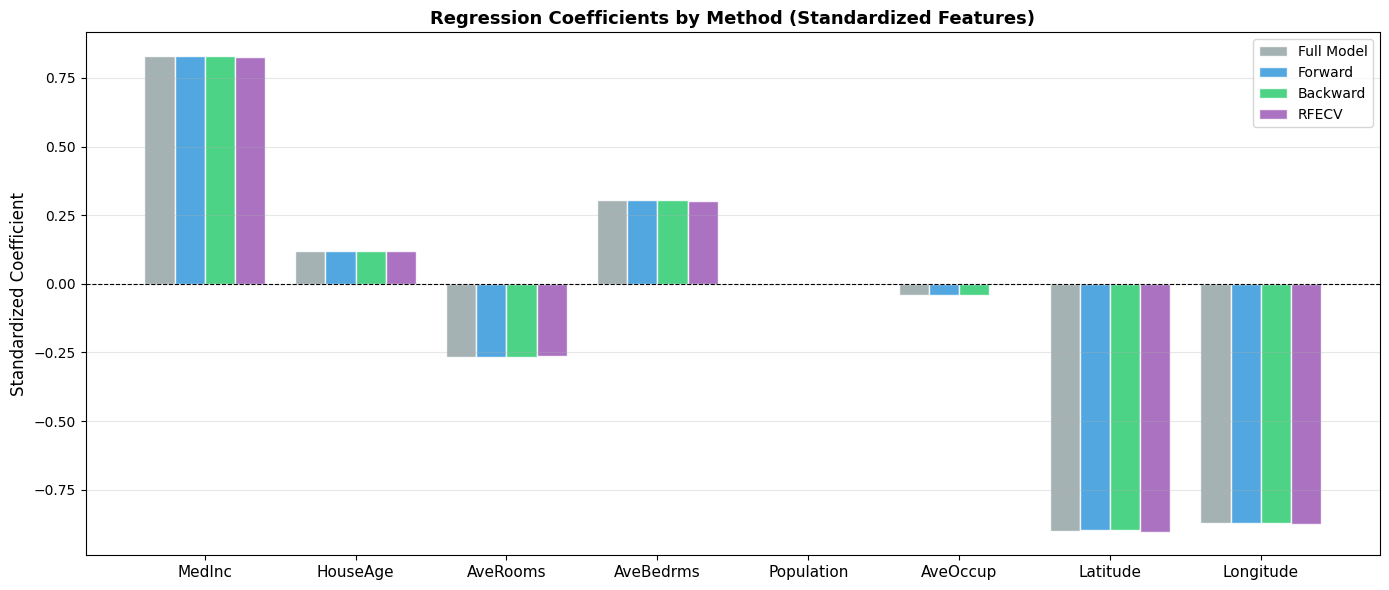

In [31]:
# Plot 2: Coefficient Comparison Across Methods
all_features = list(X_scaled.columns)
coef_data = {}

for name, feats, model_obj in [
    ('Full Model', all_features, full_model),
    ('Forward', fwd_features, fwd_model),
    ('Backward', bwd_features, bwd_model),
    ('RFECV', rfecv_features, rfecv_model)
]:
    coefs = {}
    for f in all_features:
        coefs[f] = model_obj.params.get(f, 0)
    coef_data[name] = coefs

coef_df = pd.DataFrame(coef_data, index=all_features)

fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(all_features))
width = 0.2
colors_c = ['#95A5A6', '#3498DB', '#2ECC71', '#9B59B6']

for i, (col, color) in enumerate(zip(coef_df.columns, colors_c)):
    ax.bar(x + i*width, coef_df[col], width, label=col, color=color, alpha=0.85, edgecolor='white')

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(all_features, fontsize=11)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_ylabel('Standardized Coefficient', fontsize=12)
ax.set_title('Regression Coefficients by Method (Standardized Features)', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('03_coefficients_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

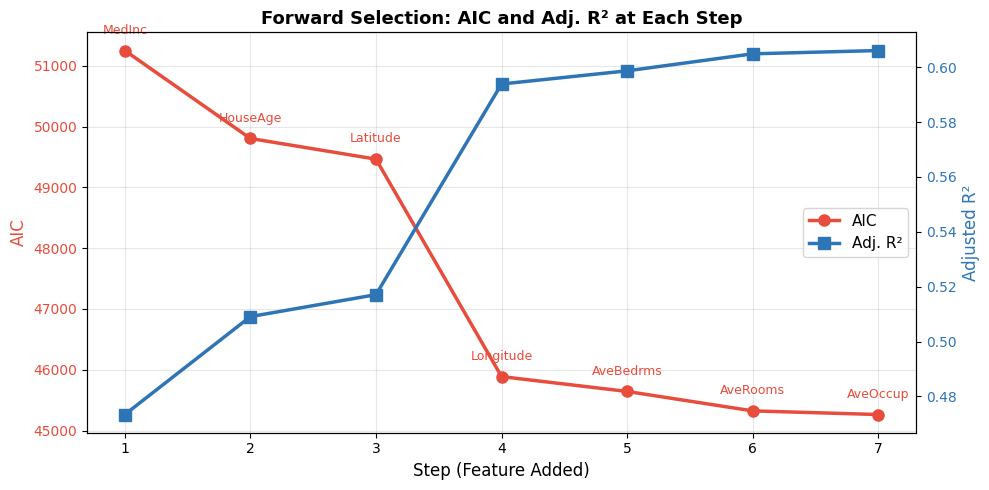

In [32]:
# Plot 3: Forward Selection - AIC and Adj. R² over steps
if len(fwd_history) > 0:
    fig, ax1 = plt.subplots(figsize=(10, 5))
    ax2 = ax1.twinx()

    steps = fwd_history['Step']
    ax1.plot(steps, fwd_history['AIC'], 'o-', color='#E74C3C', lw=2.5, ms=8, label='AIC')
    ax2.plot(steps, fwd_history['Adj. R²'], 's-', color='#2E75B6', lw=2.5, ms=8, label='Adj. R²')

    ax1.set_xlabel('Step (Feature Added)', fontsize=12)
    ax1.set_ylabel('AIC', color='#E74C3C', fontsize=12)
    ax2.set_ylabel('Adjusted R²', color='#2E75B6', fontsize=12)
    ax1.tick_params(axis='y', labelcolor='#E74C3C')
    ax2.tick_params(axis='y', labelcolor='#2E75B6')

    for i, row in fwd_history.iterrows():
        ax1.annotate(row['Feature Added'], (row['Step'], row['AIC']),
                     textcoords='offset points', xytext=(0, 12),
                     ha='center', fontsize=9, color='#E74C3C')

    ax1.set_title('Forward Selection: AIC and Adj. R² at Each Step', fontsize=13, fontweight='bold')
    ax1.set_xticks(steps)
    ax1.grid(True, alpha=0.3)

    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, fontsize=11, loc='center right')

    plt.tight_layout()
    plt.savefig('04_forward_steps.png', dpi=150, bbox_inches='tight')
    plt.show()

---
## 🔍 Section 10: Model Assumptions Check (RFECV Model)

After variable selection, always verify that linear regression assumptions hold.

| Assumption | Test |
|------------|------|
| Linearity | Residuals vs. Fitted plot |
| Normality of errors | Q-Q plot + Shapiro-Wilk |
| Homoscedasticity | Scale-Location plot + Breusch-Pagan |
| No multicollinearity | VIF (Variance Inflation Factor) |
| Independence of errors | Durbin-Watson statistic |

In [33]:
# VIF Calculation
def compute_vif(X_df):
    vif_data = pd.DataFrame()
    vif_data['Feature'] = X_df.columns
    vif_data['VIF'] = [variance_inflation_factor(X_df.values, i)
                       for i in range(X_df.shape[1])]
    vif_data['Flag'] = vif_data['VIF'].apply(
        lambda v: '🔴 High (>10)' if v > 10 else ('🟡 Moderate (5-10)' if v > 5 else '🟢 OK (<5)')
    )
    return vif_data.sort_values('VIF', ascending=False)

print('VIF — RFECV Selected Features:')
vif_rfecv = compute_vif(X_scaled[rfecv_features])
print(vif_rfecv.to_string(index=False))

print('\nVIF — Full Model:')
vif_full = compute_vif(X_scaled)
print(vif_full.to_string(index=False))

VIF — RFECV Selected Features:
  Feature      VIF              Flag
 Latitude 9.192203 🟡 Moderate (5-10)
Longitude 8.904293 🟡 Moderate (5-10)
 AveRooms 8.325484 🟡 Moderate (5-10)
AveBedrms 6.991926 🟡 Moderate (5-10)
   MedInc 2.497172         🟢 OK (<5)
 HouseAge 1.113431         🟢 OK (<5)

VIF — Full Model:
   Feature      VIF              Flag
  Latitude 9.297624 🟡 Moderate (5-10)
 Longitude 8.962263 🟡 Moderate (5-10)
  AveRooms 8.342786 🟡 Moderate (5-10)
 AveBedrms 6.994995 🟡 Moderate (5-10)
    MedInc 2.501295         🟢 OK (<5)
  HouseAge 1.241254         🟢 OK (<5)
Population 1.138125         🟢 OK (<5)
  AveOccup 1.008324         🟢 OK (<5)


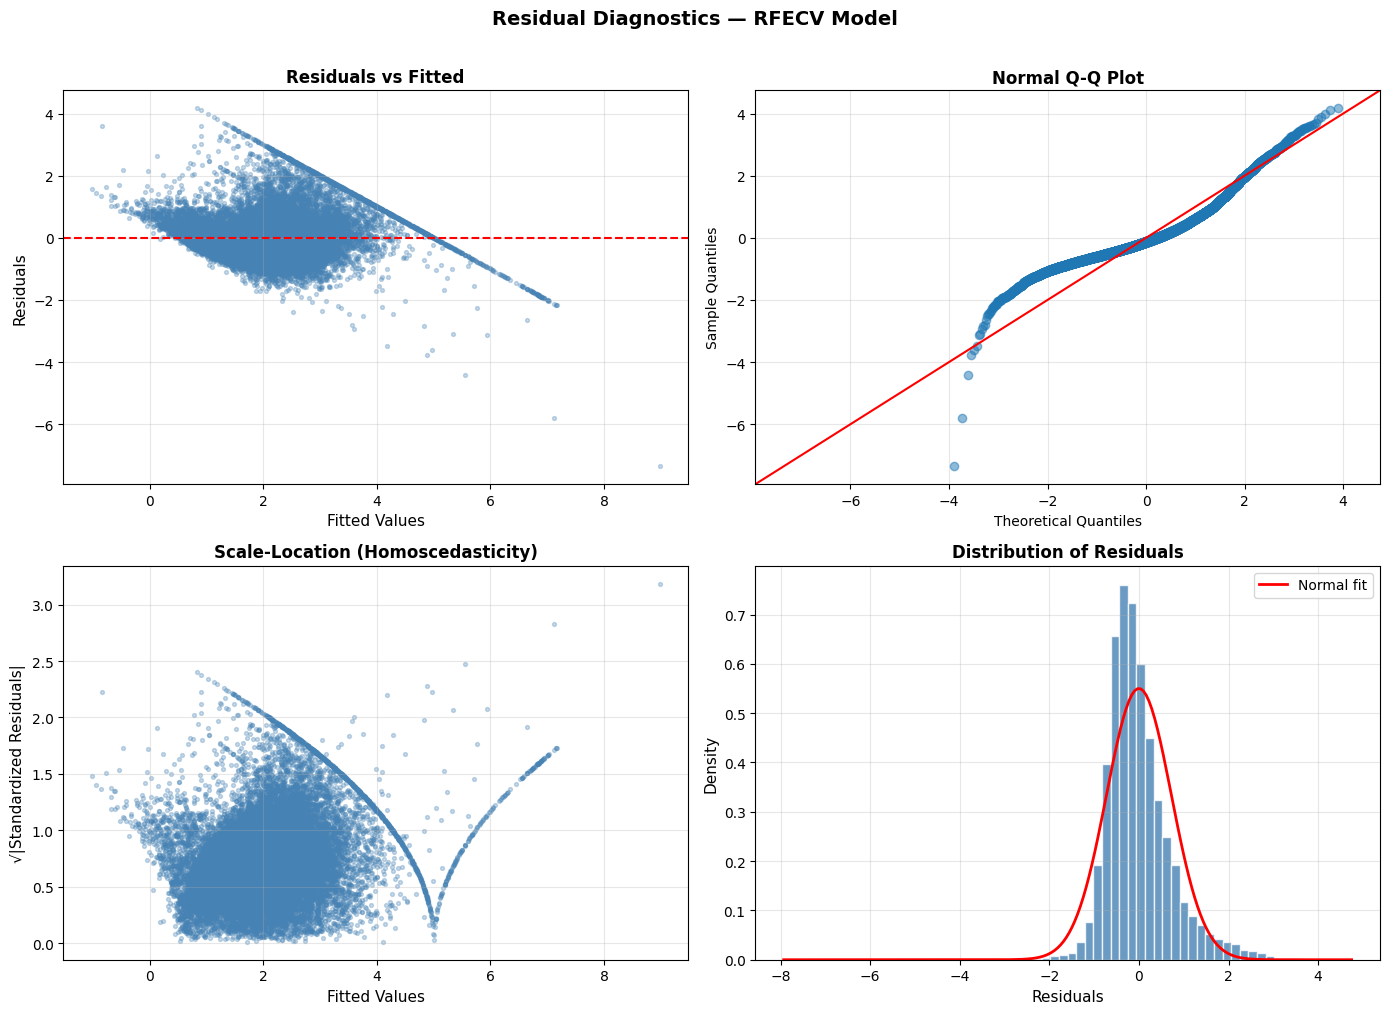


📊 Statistical Tests:
   Durbin-Watson statistic : 0.8832  (2.0 = no autocorrelation)
   Breusch-Pagan p-value   : 0.0000  (< 0.05 = heteroscedasticity present)
   Shapiro-Wilk p-value    : 0.0000  (< 0.05 = non-normal residuals)


In [34]:
# Residual Diagnostics for RFECV Model
residuals  = rfecv_model.resid
fitted     = rfecv_model.fittedvalues
std_resid  = residuals / residuals.std()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Residuals vs Fitted
axes[0, 0].scatter(fitted, residuals, alpha=0.3, color='steelblue', s=8)
axes[0, 0].axhline(0, color='red', linestyle='--', lw=1.5)
axes[0, 0].set_xlabel('Fitted Values', fontsize=11)
axes[0, 0].set_ylabel('Residuals', fontsize=11)
axes[0, 0].set_title('Residuals vs Fitted', fontsize=12, fontweight='bold')
axes[0, 0].grid(True, alpha=0.3)

# 2. Q-Q Plot
sm.qqplot(residuals, line='45', ax=axes[0, 1], alpha=0.5)
axes[0, 1].set_title('Normal Q-Q Plot', fontsize=12, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3)

# 3. Scale-Location
axes[1, 0].scatter(fitted, np.sqrt(np.abs(std_resid)), alpha=0.3, color='steelblue', s=8)
axes[1, 0].set_xlabel('Fitted Values', fontsize=11)
axes[1, 0].set_ylabel('√|Standardized Residuals|', fontsize=11)
axes[1, 0].set_title('Scale-Location (Homoscedasticity)', fontsize=12, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)

# 4. Residuals Histogram
axes[1, 1].hist(residuals, bins=60, color='steelblue', edgecolor='white', alpha=0.8, density=True)
xmin, xmax = axes[1, 1].get_xlim()
xs = np.linspace(xmin, xmax, 200)
axes[1, 1].plot(xs, stats.norm.pdf(xs, residuals.mean(), residuals.std()),
                'r-', lw=2, label='Normal fit')
axes[1, 1].set_xlabel('Residuals', fontsize=11)
axes[1, 1].set_ylabel('Density', fontsize=11)
axes[1, 1].set_title('Distribution of Residuals', fontsize=12, fontweight='bold')
axes[1, 1].legend(fontsize=10)
axes[1, 1].grid(True, alpha=0.3)

plt.suptitle('Residual Diagnostics — RFECV Model', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('05_residual_diagnostics.png', dpi=150, bbox_inches='tight')
plt.show()

# Statistical Tests
print('\n📊 Statistical Tests:')
dw = durbin_watson(residuals)
_, bp_pval, _, _ = het_breuschpagan(residuals, rfecv_model.model.exog)
_, sw_pval = stats.shapiro(residuals[:5000])   # Shapiro-Wilk (sample)

print(f'   Durbin-Watson statistic : {dw:.4f}  (2.0 = no autocorrelation)')
print(f'   Breusch-Pagan p-value   : {bp_pval:.4f}  (< 0.05 = heteroscedasticity present)')
print(f'   Shapiro-Wilk p-value    : {sw_pval:.4f}  (< 0.05 = non-normal residuals)')

---
## ✅ Section 11: Conclusion & Best Practices

### Summary of Methods

| Method | Start | Direction | Criterion | Best For |
|--------|-------|-----------|-----------|----------|
| **Forward Selection** | Empty model | Adds variables | p-value / AIC | Exploratory, large p |
| **Backward Elimination** | Full model | Removes variables | p-value / AIC | p < n, full exploration |
| **RFE** | Full model | Removes variables | Feature importance | ML pipelines |
| **RFECV** | Full model | Removes variables | CV score | Automatic selection |

### Key Takeaways

1. **Standardize features** before running any variable selection — raw coefficients are scale-dependent.
2. **No single method is universally best** — compare methods and look for consensus.
3. **RFECV is preferred** in ML pipelines because it avoids overfitting the feature count to training data.
4. **Always check VIF** after selection — VIF > 10 signals multicollinearity even if p-values look good.
5. **Validate on test data** — a high training R² with poor test R² means overfitting.
6. **Domain knowledge matters** — a statistically borderline variable may still be theoretically essential.
7. **Check residual diagnostics** after selection — variable selection doesn't fix violated assumptions.

In [ ]:
# Final Summary Print
print('=' * 70)
print('FINAL SUMMARY — VARIABLE SELECTION RESULTS')
print('=' * 70)
print(f'Dataset            : California Housing (n={len(X)}, p={len(X.columns)})')
print(f'\nForward Selection  : {len(fwd_features)} features  → {fwd_features}')
print(f'Backward Elim.     : {len(bwd_features)} features  → {bwd_features}')
print(f'RFE (n=5)          : {len(rfe_features)} features  → {rfe_features}')
print(f'RFECV (auto)       : {len(rfecv_features)} features  → {rfecv_features}')

print('\n' + '-' * 70)
print(f'{"Method":<25} {"N":<5} {"Train R²":<12} {"Test R²":<12} {"AIC"}')
print('-' * 70)
for r in results:
    print(f'{r["Method"]:<25} {r["N Features"]:<5} {r["Train R²"]:<12} {r["Test R²"]:<12} {r["AIC"]}')
print('=' * 70)
print('✅ Analysis complete!')